In [1]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

In [2]:
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS=3
EPOCHS=15

In [3]:
input_shape = (640, 640, 3)

In [4]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    r'/home/smartcity_sp7/praveen/sc_3_wli_data_classes',
    shuffle=True,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 954 files belonging to 3 classes.


In [5]:
class_names = dataset.class_names
class_names

['AK', 'BCC', 'SK']

In [6]:
for image_batch, labels_batch in dataset.take(1):
    print(image_batch.shape)
    print(labels_batch.numpy())

(32, 640, 640, 3)
[0 0 1 1 0 1 1 1 0 1 2 2 2 2 2 0 2 0 2 2 1 0 1 1 2 0 2 1 0 2 2 2]


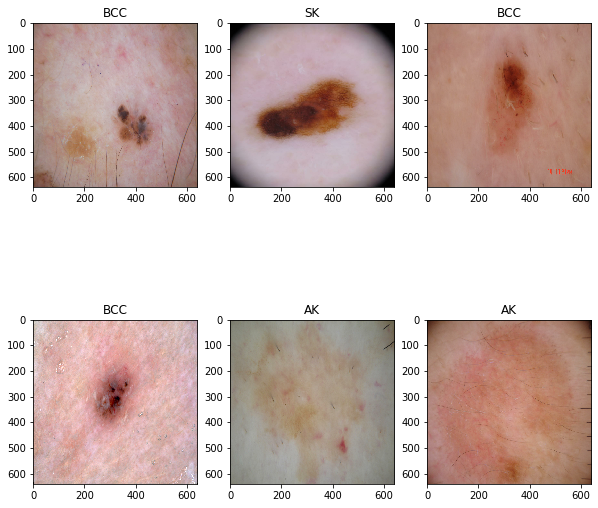

In [9]:
plt.figure(figsize=(10, 10))
for image_batch, labels_batch in dataset.take(1):
    for i in range (6):
        plt.subplot(2,3,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[labels_batch[i]])

In [10]:
def get_dataset_partitions_tf(ds, train_split=0.8, val_split=0.05, test_split=0.15, shuffle=True, shuffle_size=10):
    assert (train_split + test_split + val_split) == 1
    ds_size = len(ds)
    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)
    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)
    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)
    return train_ds, val_ds, test_ds

In [11]:
train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)

In [12]:
len(train_ds)

24

In [13]:
len(test_ds)

5

In [14]:
resize_and_rescale = tf.keras.Sequential([
  layers.experimental.preprocessing.Resizing(IMAGE_SIZE, IMAGE_SIZE),
  layers.experimental.preprocessing.Rescaling(1./255),
])

In [15]:
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = models.Sequential([
    resize_and_rescale,
    layers.Conv2D(32, kernel_size = (3,3), activation='relu', input_shape=[640,640,3]),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])

model.build(input_shape=input_shape)

In [16]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [17]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential (Sequential)     (32, 640, 640, 3)         0         
                                                                 
 conv2d (Conv2D)             (32, 638, 638, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2D  (32, 319, 319, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (32, 317, 317, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (32, 158, 158, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (32, 156, 156, 64)       

In [18]:
model.fit(
    train_ds,
    verbose=1,
    epochs=15,
)

Epoch 1/15
24/24 [==============================] - 199s 8s/step - loss: 1.2690 - accuracy: 0.3112
Epoch 2/15
24/24 [==============================] - 256s 11s/step - loss: 1.0917 - accuracy: 0.3542
Epoch 3/15
24/24 [==============================] - 284s 11s/step - loss: 1.0368 - accuracy: 0.4541
Epoch 4/15
24/24 [==============================] - 269s 11s/step - loss: 0.9597 - accuracy: 0.5742
Epoch 5/15
24/24 [==============================] - 284s 11s/step - loss: 0.9117 - accuracy: 0.5656
Epoch 6/15
24/24 [==============================] - 285s 12s/step - loss: 0.8138 - accuracy: 0.6273
Epoch 7/15
24/24 [==============================] - 271s 11s/step - loss: 0.7259 - accuracy: 0.6758
Epoch 8/15
24/24 [==============================] - 286s 12s/step - loss: 0.6633 - accuracy: 0.7227
Epoch 9/15
24/24 [==============================] - 290s 12s/step - loss: 0.5815 - accuracy: 0.7454
Epoch 10/15
24/24 [==============================] - 289s 12s/step - loss: 0.5175 - accuracy: 0.7913


In [19]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array, 0)
    predictions = model.predict(img_array)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

1/1 [==============================] - 0s 111ms/step


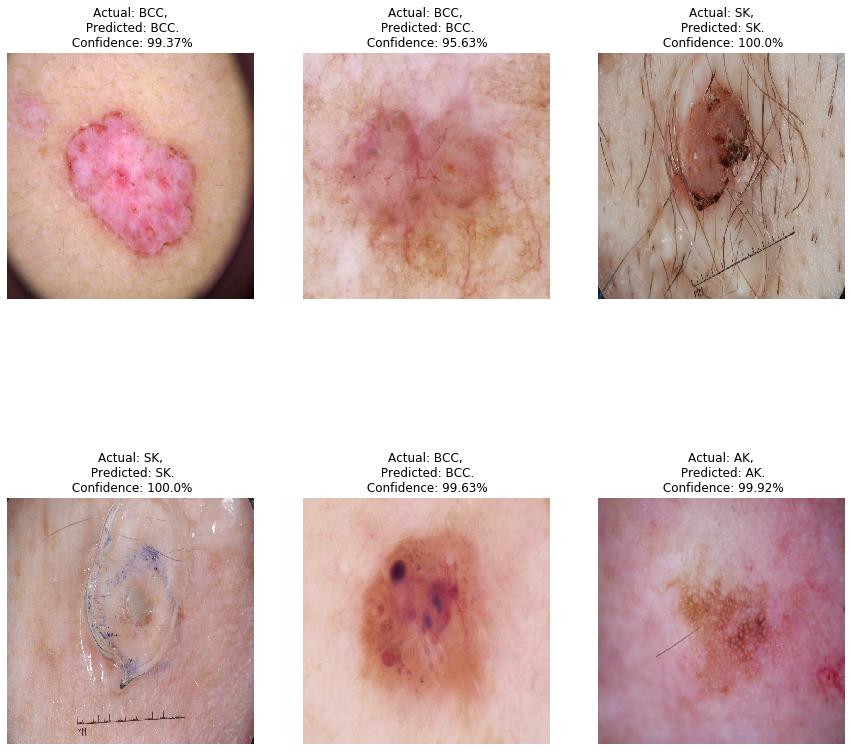

In [21]:
import numpy as np


plt.figure(figsize=(15, 15))
for images, labels in test_ds.take(1):
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]]
        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")
        plt.axis("off")

In [22]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
y_pred = []
y_true = []
for images, labels in test_ds:
    predictions = model.predict(images)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())
y_true = np.array(y_true)
y_pred = np.array(y_pred)

1/1 [==============================] - 2s 2s/step


In [23]:
report = classification_report(y_true, y_pred, target_names=class_names)
print("Classification Report:\n\n", report)

Classification Report:

               precision    recall  f1-score   support

          AK       0.91      0.96      0.94        55
         BCC       0.96      0.91      0.93        54
          SK       0.96      0.96      0.96        51

    accuracy                           0.94       160
   macro avg       0.95      0.94      0.94       160
weighted avg       0.94      0.94      0.94       160



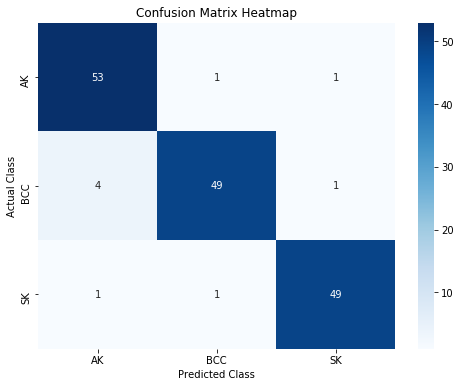

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, columns=class_names, index=class_names)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap")
plt.show()